In [320]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from scipy import stats

df = pd.read_excel('./Employee_dataset.xlsx',sheet_name='Sheet1')
df.head()

,Column1,Employee_ID,First_Name,Last_Name,Age,Department_Region,Status,Join_Date,Salary,Email,Phone,Performance_Score,Remote_Work,date_Clean,Department,Location_Department,Standart_Gaji,Column2
0,0,EMP1000,Bob,Davis,25,DevOps-California,Active,04/02/2021,59767.65,bob.davis@example.com,-1651623197,Average,True,2021-04-02,DevOps,California,Underpaid,NaN
1,1,EMP1001,Bob,Brown,32,Finance-Texas,Active,07/10/2020,65304.66,bob.brown@example.com,-1898471390,Excellent,True,2020-07-10,Finance,Texas,Standart,NaN
2,2,EMP1002,Alice,Jones,32,Admin-Nevada,Pending,12/07/2023,88145.90,alice.jones@example.com,-5596363211,Good,True,2023-12-07,Admin,Nevada,Overpaid,NaN
3,3,EMP1003,Eva,Davis,25,Admin-Nevada,Inactive,11/27/2021,69450.99,eva.davis@example.com,-3476490784,Good,True,2021-11-27,Admin,Nevada,Standart,NaN
4,4,EMP1004,Frank,Williams,25,Cloud Tech-Florida,Active,01/05/2022,109324.61,frank.williams@example.com,-1586734256,Poor,False,2022-01-05,Cloud Tech,Florida,Standart,NaN


In [294]:
standart_salary = pd.read_excel('./Employee_dataset.xlsx',sheet_name='SALARY')
standart_salary.head()

,Departmen,Minimum_Salary,Maximum_salary
0,Admin,40000,75000
1,Cloud Tech,80000,130000
2,DevOps,85000,140000
3,Finance,60000,105000
4,HR,50000,85000


In [287]:
df = df.drop(columns=['Column2','Email','Department_Region','Phone','Column1','Join_Date'],errors='ignore')
df

,Employee_ID,First_Name,Last_Name,Age,Status,Salary,Performance_Score,Remote_Work,date_Clean,Department,Location_Department,Standart_Gaji
0,EMP1000,Bob,Davis,25,Active,59767.65,Average,True,2021-04-02,DevOps,California,Underpaid
1,EMP1001,Bob,Brown,32,Active,65304.66,Excellent,True,2020-07-10,Finance,Texas,Standart
2,EMP1002,Alice,Jones,32,Pending,88145.90,Good,True,2023-12-07,Admin,Nevada,Overpaid
3,EMP1003,Eva,Davis,25,Inactive,69450.99,Good,True,2021-11-27,Admin,Nevada,Standart
4,EMP1004,Frank,Williams,25,Active,109324.61,Poor,False,2022-01-05,Cloud Tech,Florida,Standart
...,...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30,Active,85165.05,Good,True,2023-08-19,HR,California,Overpaid
1016,EMP2016,David,Johnson,30,Inactive,100215.06,Good,True,2021-11-07,Cloud Tech,Texas,Standart
1017,EMP2017,Charlie,Williams,40,Active,114587.11,Average,False,2023-10-04,Finance,New York,Overpaid
1018,EMP2018,Alice,Garcia,30,Inactive,71318.79,Good,True,2024-12-16,HR,Florida,Standart


In [288]:
df_band = pd.merge(df,standart_salary, on='Department', how='left')
df_band

,Employee_ID,First_Name,Last_Name,Age,Status,Salary,Performance_Score,Remote_Work,date_Clean,Department,Location_Department,Standart_Gaji,Minimum_Salary,Maximum_salary
0,EMP1000,Bob,Davis,25,Active,59767.65,Average,True,2021-04-02,DevOps,California,Underpaid,85000,140000
1,EMP1001,Bob,Brown,32,Active,65304.66,Excellent,True,2020-07-10,Finance,Texas,Standart,60000,105000
2,EMP1002,Alice,Jones,32,Pending,88145.90,Good,True,2023-12-07,Admin,Nevada,Overpaid,40000,75000
3,EMP1003,Eva,Davis,25,Inactive,69450.99,Good,True,2021-11-27,Admin,Nevada,Standart,40000,75000
4,EMP1004,Frank,Williams,25,Active,109324.61,Poor,False,2022-01-05,Cloud Tech,Florida,Standart,80000,130000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,EMP2015,David,Miller,30,Active,85165.05,Good,True,2023-08-19,HR,California,Overpaid,50000,85000
1016,EMP2016,David,Johnson,30,Inactive,100215.06,Good,True,2021-11-07,Cloud Tech,Texas,Standart,80000,130000
1017,EMP2017,Charlie,Williams,40,Active,114587.11,Average,False,2023-10-04,Finance,New York,Overpaid,60000,105000
1018,EMP2018,Alice,Garcia,30,Inactive,71318.79,Good,True,2024-12-16,HR,Florida,Standart,50000,85000


In [289]:
df_band.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Employee_ID          1020 non-null   str           
 1   First_Name           1020 non-null   str           
 2   Last_Name            1020 non-null   str           
 3   Age                  1020 non-null   int64         
 4   Status               1020 non-null   str           
 5   Salary               1020 non-null   float64       
 6   Performance_Score    1020 non-null   str           
 7   Remote_Work          1020 non-null   bool          
 8   date_Clean           1020 non-null   datetime64[us]
 9   Department           1020 non-null   str           
 10  Location_Department  1020 non-null   str           
 11  Standart_Gaji        1020 non-null   str           
 12  Minimum_Salary       1020 non-null   int64         
 13  Maximum_salary       1020 non-null   int64  

In [293]:
print(f"Duplicated Row : {df_band.duplicated().sum()}")

Duplicated Row : 0


In [290]:
print(f'Rata rata gaji : {df_band['Salary'].mean():.0f}')

Rata rata gaji : 85155


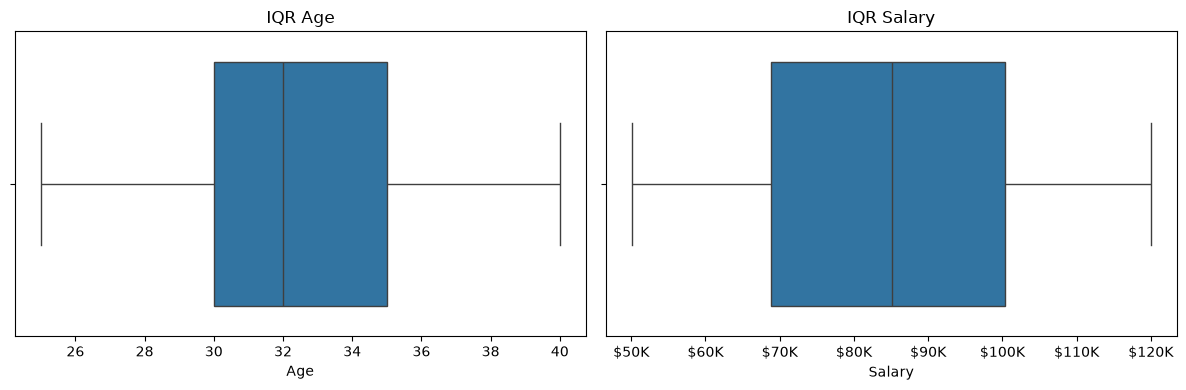

In [302]:
fig,ax= plt.subplots(1,2,figsize=(12,4))
sns.boxplot(df_band,x='Age', ax=ax[0])
ax[0].set_title('IQR Age')
sns.boxplot(df_band,x='Salary',ax=ax[1])
ax[1].set_title('IQR Salary')
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(currency_fmt))
plt.tight_layout()
plt.show()

In [306]:
df[['Age','Salary']].describe().round(0)

,Age,Salary
count,1020.0,1020.0
mean,32.0,85155.0
std,5.0,19638.0
min,25.0,50047.0
25%,30.0,68811.0
50%,32.0,85165.0
75%,35.0,100373.0
max,40.0,119972.0


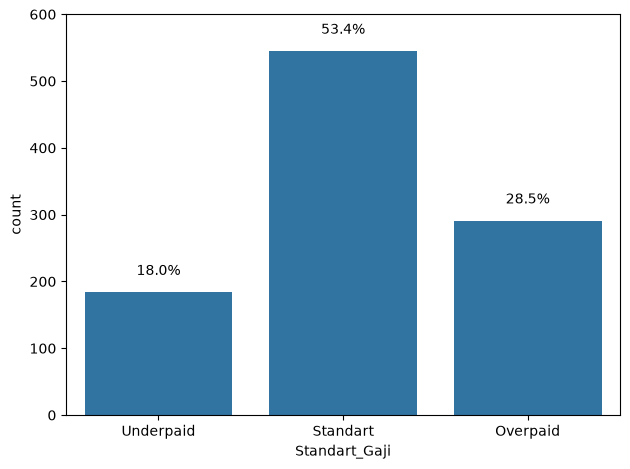

In [280]:
ax = sns.countplot(data=df, x='Standart_Gaji')
total = len(df)
for container in ax.containers:
    labels = [f'{(v.get_height() / total) * 100:.1f}%' for v in container]
    ax.bar_label(container, labels=labels, padding=10)
    plt.ylim(0, 600)
plt.tight_layout()
plt.show()

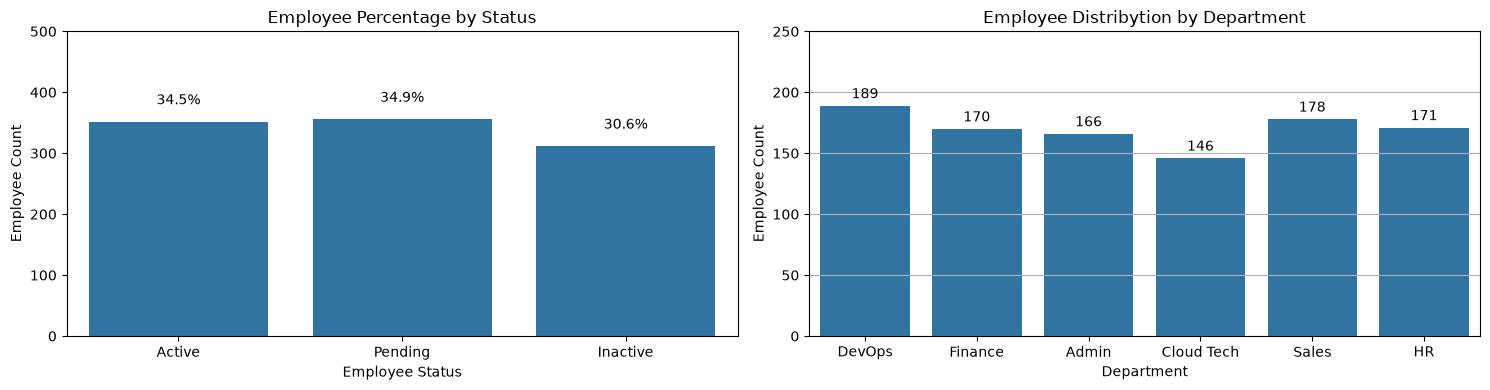

In [ ]:
fig,axe=plt.subplots(1,2,figsize=(15,4)) 

ax = sns.countplot(data=df, x='Status',ax=axe[0])
total = len(df)
for container in ax.containers:
    labels = [f'{(v.get_height() / total) * 100:.1f}%' for v in container]
    ax.bar_label(container, labels=labels, padding=10)

axe[0].set_title('Employee Percentage by Status')
axe[0].set_xlabel('Employee Status')
axe[0].set_ylabel('Employee Count')
axe[0].set_ylim(0, 500)
ax = sns.countplot(data=df, x='Department',ax=axe[1])
plt.bar_label(ax.containers[0], padding=3)
axe[1].set_title('Employee Distribytion by Department')
axe[1].set_xlabel('Department')
axe[1].set_ylabel('Employee Count')
axe[1].set_ylim(0, 250)
plt.tight_layout()
plt.show()

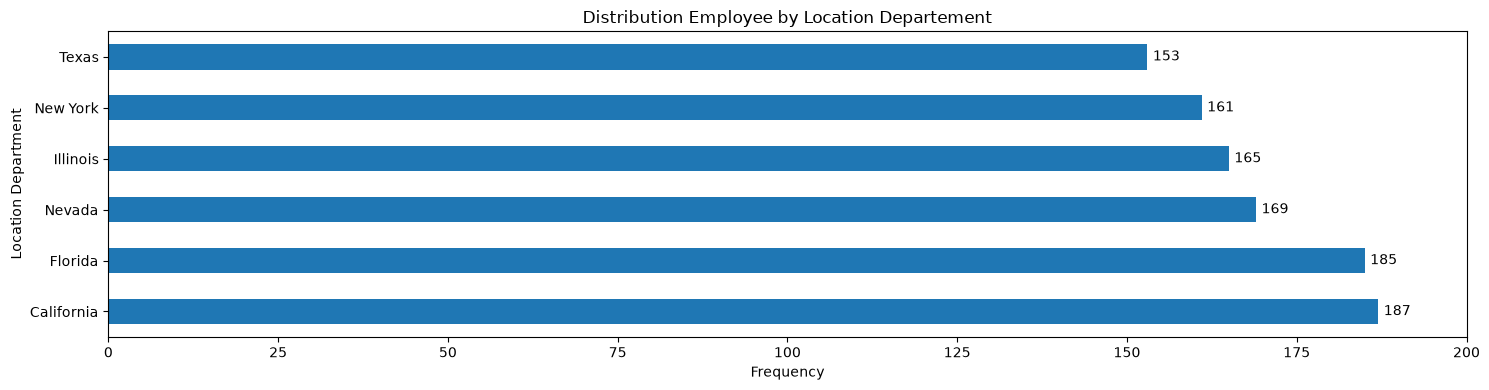

In [325]:
plt.figure(figsize=(15,4))
ax=df['Location_Department'].value_counts().plot(kind='barh')
plt.bar_label(ax.containers[0],padding=4)
plt.title('Distribution Employee by Location Departement')
plt.ylabel('Location Department')
plt.xlabel('Frequency')
plt.xlim(0,200)

plt.tight_layout()

plt.show()

In [228]:
df.groupby('Location_Department')['Salary'].mean().round(0)

Location_Department
California    86612.0
Florida       86286.0
Illinois      85275.0
Nevada        83634.0
New York      83789.0
Texas         84998.0
Name: Salary, dtype: float64

In [ ]:
def currency_fmt(x, pos):
    if x >= 1e6:
        return f'${x*1e-6:.1f}M'
    elif x >= 1e3:
        return f'${x*1e-3:.0f}K'
    return f'${x:.0f}'

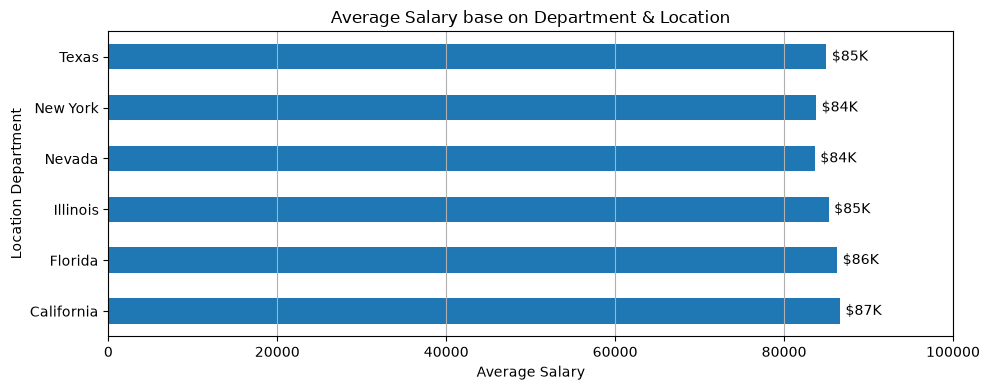

Range: 50,047 - 119,972 | ANOVA salary ~ location: F = 0.69, p = 0.632


In [326]:
avg_salary_loc = df.groupby('Location_Department')['Salary'].mean().round()
plt.figure(figsize=(10, 4))  
ax=avg_salary_loc.plot(kind='barh')
plt.bar_label(ax.containers[0],padding=4,labels=[currency_fmt(val, None) for val in avg_salary_loc])
plt.title('Average Salary base on Department & Location')
plt.ylabel('Location Department')
plt.xlabel('Average Salary')
plt.xlim(0,100000)
plt.tight_layout()
plt.grid(axis='x')
plt.show()
f_loc, p_loc = stats.f_oneway(*[g['Salary'].values for _, g in df.groupby('Location_Department')])
print(f'Range: {df_band['Salary'].min():,.0f} - {df_band['Salary'].max():,.0f} | ANOVA salary ~ location: F = {f_loc:.2f}, p = {p_loc:.3f}')

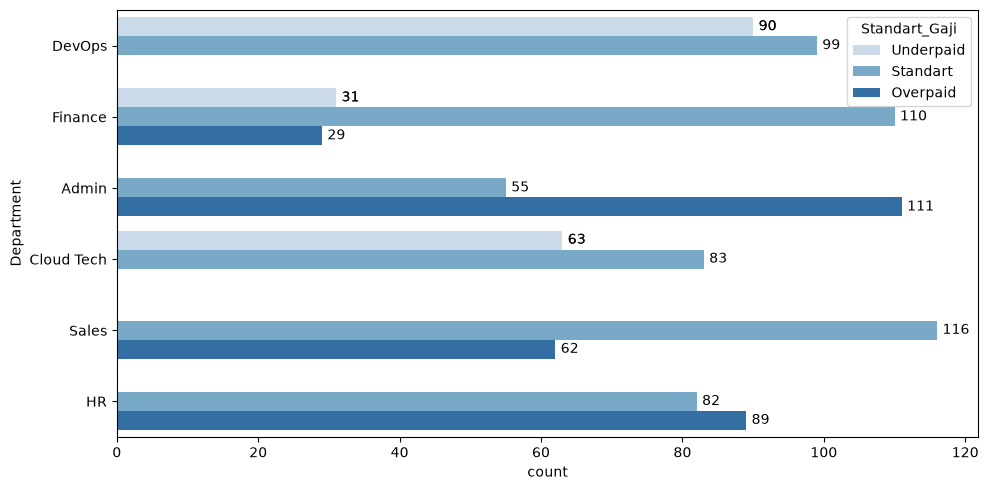

In [327]:
fig, ax = plt.subplots(figsize=(10, 5))
ax=sns.countplot(data=df,y='Department',hue='Standart_Gaji' ,palette='Blues')
plt.tight_layout()
plt.bar_label(ax.containers[0],padding=4)
for container in ax.containers:
  ax.bar_label(container, padding=4, fmt='%d')
plt.show()

In [231]:
salary_median_per_performance=df.groupby('Performance_Score')['Salary'].median()
salary_mean_per_performance=df.groupby('Performance_Score')['Salary'].mean()

print(salary_mean_per_performance)
print()
print(salary_median_per_performance)

Performance_Score
Average      84204.999663
Excellent    85047.907453
Good         86295.287963
Poor         85037.701019
Name: Salary, dtype: float64

Performance_Score
Average      84913.18
Excellent    84894.52
Good         85984.11
Poor         85394.94
Name: Salary, dtype: float64


Text(0.5, 1.0, 'Median salary per performance')

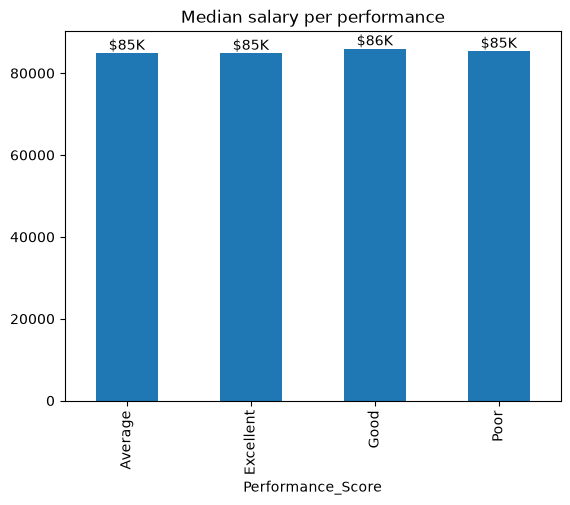

In [259]:
ax=salary_median_per_performance.plot(kind='bar')
plt.bar_label(ax.containers[0],labels=[currency_fmt(val, None) for val in salary_median_per_performance])
plt.title("Median salary per performance")

Text(0.5, 1.0, 'Average salary per performance')

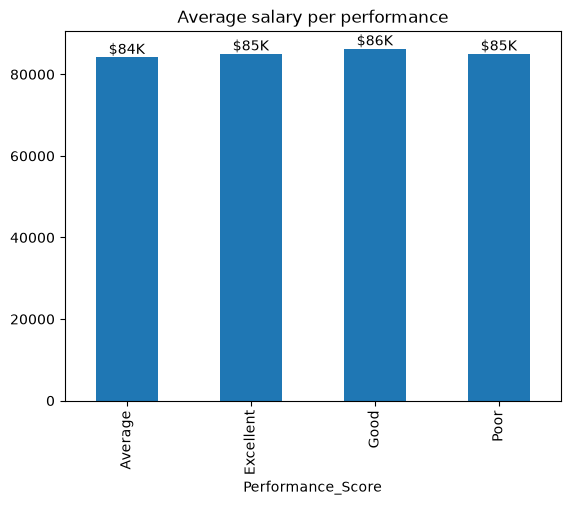

In [260]:
ax=salary_mean_per_performance.plot(kind='bar')
plt.bar_label(ax.containers[0],labels=[currency_fmt(val, None) for val in salary_mean_per_performance])
plt.title("Average salary per performance")

In [234]:
crostab_performance_salary = pd.crosstab(df['Standart_Gaji'],df['Performance_Score'])
crostab_performance_salary

Performance_Score,Average,Excellent,Good,Poor
Standart_Gaji,,,,
Overpaid,66,78,85,62
Standart,151,146,135,113
Underpaid,50,43,50,41


In [235]:
crostab_persen = pd.crosstab( df['Performance_Score'],df['Standart_Gaji'], normalize='index') * 100

crostab_persen.round(2)

Standart_Gaji,Overpaid,Standart,Underpaid
Performance_Score,,,
Average,24.72,56.55,18.73
Excellent,29.21,54.68,16.10
Good,31.48,50.00,18.52
Poor,28.70,52.31,18.98


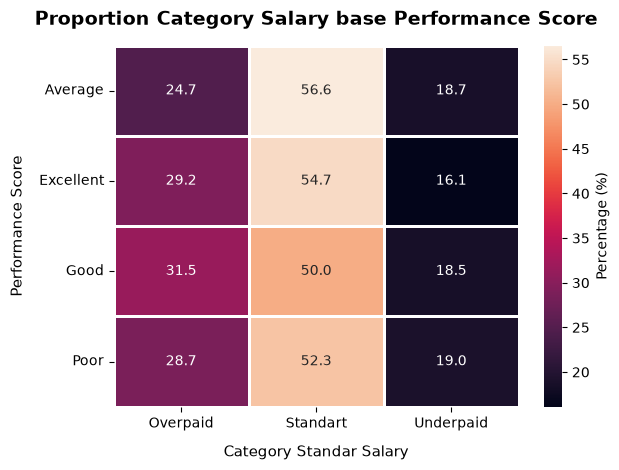

In [236]:
sns.heatmap(crostab_persen, annot=True, fmt='.1f',cbar_kws={'label': 'Percentage (%)'},linewidths=1, linecolor='white')
plt.title('Proportion Category Salary base Performance Score', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Category Standar Salary', fontsize=11, labelpad=10)
plt.ylabel('Performance Score', fontsize=11, labelpad=10)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:


gaji_Average = df[df['Performance_Score']=='Average']['Salary']
gaji_Excellent = df[df['Performance_Score']=='Excellent']['Salary']
gaji_Good = df[df['Performance_Score']=='Good']['Salary']
gaji_Poor = df[df['Performance_Score']=='Poor']['Salary']

f_stat,p_value = stats.f_oneway(gaji_Average,gaji_Excellent,gaji_Good,gaji_Poor)

print(f'F-Stat  : {f_stat}')
print(f'P-Value : {p_value}')

if p_value < 0.05 :
    print("Kesimpulan: Ada perbedaan rata-rata gaji yang signifikan antar level performa.")
else:
    print("Kesimpulan: Tidak ada perbedaan rata-rata gaji yang signifikan antar level performa.")

F-Stat  : 0.5161843953764436
P-Value : 0.6712060934915878
Kesimpulan: Tidak ada perbedaan rata-rata gaji yang signifikan antar level performa.


In [238]:
standart_salary = standart_salary.rename(columns={'Departmen': 'Department'})


In [241]:
df_band['gap_min'] = (df_band['Minimum_Salary'] - df_band['Salary'] ).clip(lower=0)
df_band['gap_over'] = (df_band['Salary']-df_band['Maximum_salary']).clip(lower=0)

In [277]:
excellent_underpaid =df_band[(df_band['Performance_Score']=='Excellent')& (df_band['gap_min']>0)]['gap_min'].count()
total_cost =df_band[(df_band['Performance_Score']=='Excellent')& (df_band['gap_min']>0)]['gap_min'].sum()
per_employee = total_cost/excellent_underpaid
print(f'Melakukan perbaikan gaji terhadap {excellent_underpaid} orang dengan total biaya {currency_fmt(total_cost, None)} perorang {currency_fmt(per_employee,None)}')

Melakukan perbaikan gaji terhadap 43 orang dengan total biaya $627K perorang $15K


In [248]:
under_per_department=df_band.groupby('Department')['gap_min'].sum()
under_per_department[under_per_department>0]

Department
Cloud Tech     878312.67
DevOps        1397858.24
Finance        179228.88
Name: gap_min, dtype: float64

In [249]:
over_per_department=df_band.groupby('Department')['gap_over'].sum()
over_per_department[over_per_department>0]

Department
Admin      2406115.54
Finance     214018.51
HR         1577434.14
Sales       799722.06
Name: gap_over, dtype: float64

In [252]:
print(f"Total Overpaid All Department : {over_per_department[over_per_department>0].sum()}")
print(f"Total Underpaid All Department : {under_per_department[under_per_department>0].sum()}")

Total Overpaid All Department : 4997290.25
Total Underpaid All Department : 2455399.79


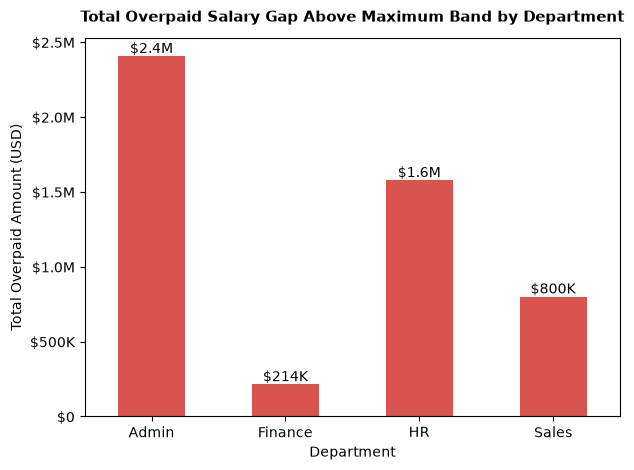

In [263]:
ax = over_per_department[over_per_department > 0].plot(kind='bar',color='#d9534f')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(currency_fmt))
plt.bar_label(ax.containers[0], labels=[currency_fmt(val, None) for val in over_per_department[over_per_department > 0]])
plt.title('Total Overpaid Salary Gap Above Maximum Band by Department', fontsize=11, fontweight='bold', pad=12)
plt.xlabel('Department', fontsize=10)
plt.ylabel('Total Overpaid Amount (USD)', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

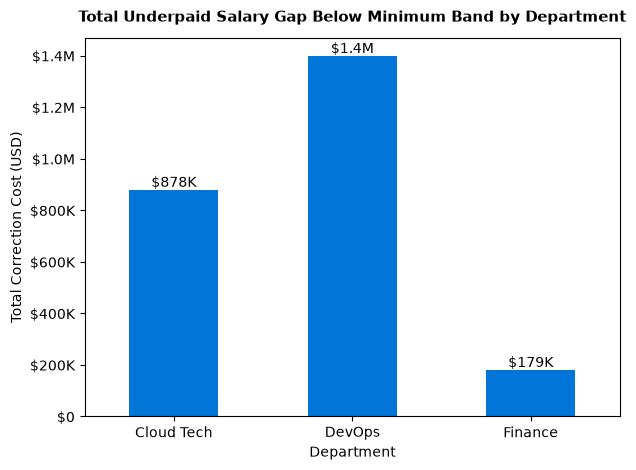

In [265]:
ax = under_per_department[under_per_department > 0].plot(kind='bar',color='#0275d8')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(currency_fmt))
plt.bar_label(ax.containers[0], labels=[currency_fmt(val, None) for val in under_per_department[under_per_department > 0]])

plt.title('Total Underpaid Salary Gap Below Minimum Band by Department', fontsize=11, fontweight='bold', pad=12)
plt.xlabel('Department', fontsize=10)
plt.ylabel('Total Correction Cost (USD)', fontsize=10)
plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()